# Store Customers Segmentation Project #

## Step 1: : Data Extraction and Cleaning ##

### Business Problem: ###

The business is relying on generic, high-cost, inefficient marketing campaigns without understanding their customers base. 

### Business Objective: ### 

Utilise unsupervised machine learning to identify shopper personas based on income and spending habits to create targeted marketing strategies.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('store_customers.csv')

# inspect the initial data state
display(df.head())
display(df.info())

print("---Missing values:---\n", df.isnull().sum())
print("---Duplicates:---", df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1000,M,39.0,59.9,58.0
1,1001,M,34.0,48.4,37.0
2,1002,F,40.0,70.5,26.0
3,1003,F,47.0,81.1,30.0
4,1004,F,33.0,42.1,58.0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              1000 non-null   int64  
 1   Gender                  997 non-null    str    
 2   Age                     994 non-null    float64
 3   Annual Income (k$)      996 non-null    float64
 4   Spending Score (1-100)  994 non-null    float64
dtypes: float64(3), int64(1), str(1)
memory usage: 39.2 KB


None

---Missing values:---
 CustomerID                0
Gender                    3
Age                       6
Annual Income (k$)        4
Spending Score (1-100)    6
dtype: int64
---Duplicates:--- 0


    As we can see we have 3 (Gender) + 6 (Age) + 4 (Income) + 6 (Spending Score) = 19 missing values 

    Which means it account for less than 2% of the whole datatset, therefore we can safely drop them rather than guessing or calculate it 

    This is to maintain data integrity

In [2]:
# drop rows with missing values 
df_clean = df.dropna().copy()

# verify the cleaning 
print("Remaining records after cleaning:", len(df_clean))
print("\nMissing values check:")
print(df_clean.isnull().sum())

Remaining records after cleaning: 982

Missing values check:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


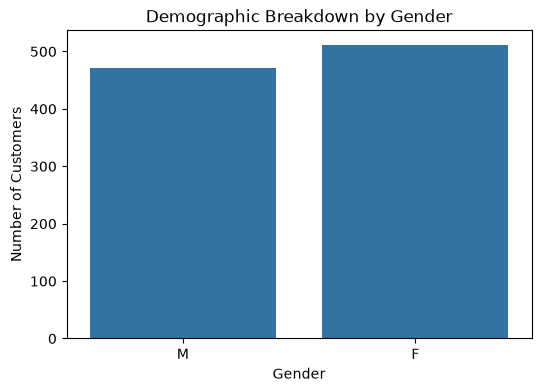

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='Gender')
plt.title('Demographic Breakdown by Gender')
plt.ylabel('Number of Customers')
plt.show()

### Observations from the Demographic Breakdown by Gender ###

> The customer base is split evenly between genders (approximately 510 females compared to roughly 470 males)
> 
> Because the ratio is almost 50/50, we can state that the overall dataset does not suffer from extreme gender bias


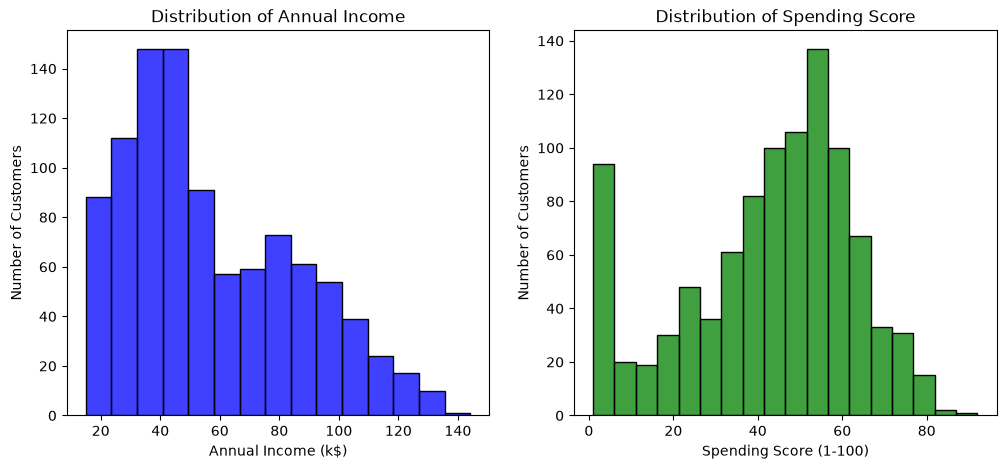

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# distribution of Annual Income
sns.histplot(df_clean['Annual Income (k$)'], ax=axes[0], color='blue')
axes[0].set_title('Distribution of Annual Income')
axes[0].set_ylabel('Number of Customers')

# distribution of Spending Score
sns.histplot(df_clean['Spending Score (1-100)'], ax=axes[1], color='green')
axes[1].set_title('Distribution of Spending Score')
axes[1].set_ylabel('Number of Customers')

plt.show()

### Observations from the "Distribution of Annual Income" ###

> The income data is heavily concentrated on the lower end, with the massive spike in the 30k–50k range
> 
> The number of customers steadily declines as income increases
> 
> There is smaller peak around the 80k mark, suggesting a distinct middle/upper-middle class customers before the numbers drop off again

### Observations from the "Distribution of Spending Score" ###

> The majority of customers fall in the middle, creating a peak between scores of 40 and 60
> 
> There is sharp spike at the low end (under 10), indicating a significant group of minimal shoppers
> 
> Unlike the lower end, the high end tapers off,  very few customers achieve a spending score above 80


## Step 2: Data Preparation and Normalisation ##

    K-Means clustering relies on Euclidean distance to measure similarity between data points 

    Because "Annual Income (k$)" and "Spending Score (1-100)" operate on different scales, failing to normalise the data would cause the feature with the larger variance to dominate the distance calculations, skewing the final customer segments. 

    See: [](https://scikit-learn.org/stable/modules/clustering.html#k-means)


In [5]:
from sklearn.preprocessing import StandardScaler

features = ['Annual Income (k$)', 'Spending Score (1-100)']

# apply standard scaling (z normalisation) 
scaler = StandardScaler()

df_scaled = df_clean.copy()
df_scaled[features] = scaler.fit_transform(df_clean[features])

# review the normalised data
display(df_scaled[features].describe().round(3))


,Annual Income (k$),Spending Score (1-100)
count,982.000,982.000
mean,-0.000,-0.000
std,1.001,1.001
min,-1.478,-2.069
25%,-0.775,-0.577
50%,-0.285,0.219
75%,0.773,0.716
max,3.029,2.456


## Step 3: Significance Testing ## 

### Hypothesis ###
    
    Null Hypothesis: There is no statistically significant difference in the average Spending Score between male and female customers
    Alternative Hypothesis: There is a statistically significant difference in the average Spending Score between male and female customers

    According to Wikipedia: "It is not recommended to pre-test for equal variances and then choose between Student's t-test or Welch's t-test. 
    Rather, Welch's t-test can be applied directly and without any substantial disadvantages to Student's t-test as noted above."

    See: [] (https://en.wikipedia.org/wiki/Welch%27s_t-test)

    With that in mind, we are applying Welch method. 

In [6]:
from scipy import stats

# isolate the Spending Score feature 
male_scores = df_clean[df_clean['Gender'] == 'M']['Spending Score (1-100)']
female_scores = df_clean[df_clean['Gender'] == 'F']['Spending Score (1-100)']

# execute Welchs t-test 
results = stats.ttest_ind(male_scores, female_scores, equal_var= False)

t_stats = results.statistic
p_value = results.pvalue

print(f"T-statistic: {t_stats.round(4):}")
print(f"P-value: {p_value.round(4):}")

T-statistic: 0.6083
P-value: 0.5431


### Null or Alternative ?? ###
    
    We found that the p-value is > 0.05. 
    Which means there is a 54.3% probability that the differences in spending scores between men and women occurred strictly by random. 
    Therefore, we have to reject the alternative hypothesis.

## Step 4: Unsupervised Learning for Clustering ##

### We are starting the benchmark model with k=2 as advised ###

In [7]:
from sklearn.cluster import KMeans

# isolate the scaled features 
data = df_scaled[['Annual Income (k$)', 'Spending Score (1-100)']]

# build the benchmark model
benchmark_model = KMeans(n_clusters= 2, random_state= 42, n_init= 'auto')
df_scaled['Benchmark_Cluster'] = benchmark_model.fit_predict(data)

print(f"Benchmark's inertia with k=2: {benchmark_model.inertia_:}")

Benchmark's inertia with k=2: 628.0667620240149


### Now we are going to find the optimal k ###

In [8]:
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_scores = []

# calculate metrics for each k
for k in range(2, 11):
    
    kmeans = KMeans(n_clusters= k, random_state= 42, n_init= 'auto')
    cluster_labels = kmeans.fit_predict(data)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(data, cluster_labels))
    

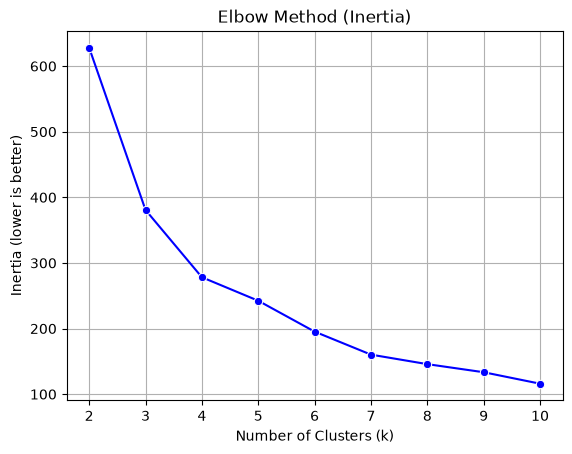

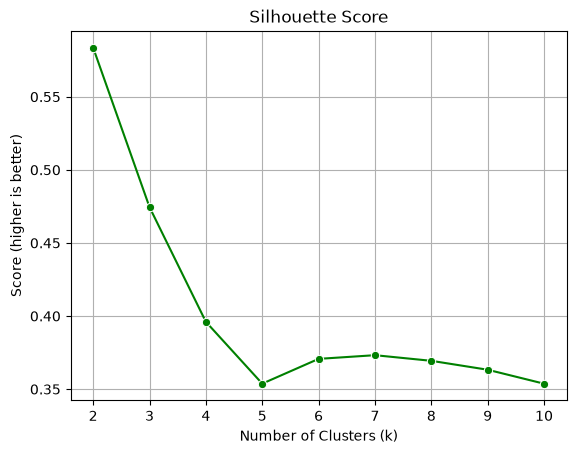

In [9]:
# draw the Elbow Chart

sns.lineplot(x= range(2, 11), y= inertia_values, marker= 'o', color= 'blue')
plt.title('Elbow Method (Inertia)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (lower is better)')
plt.grid(True)
plt.show()

# draw the Silhouette Score Chart

sns.lineplot(x= range(2, 11), y= silhouette_scores, marker= 'o', color= 'green')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Score (higher is better)')
plt.grid(True)
plt.show()

**For better readability, we are going to combine the 2 charts into 1**

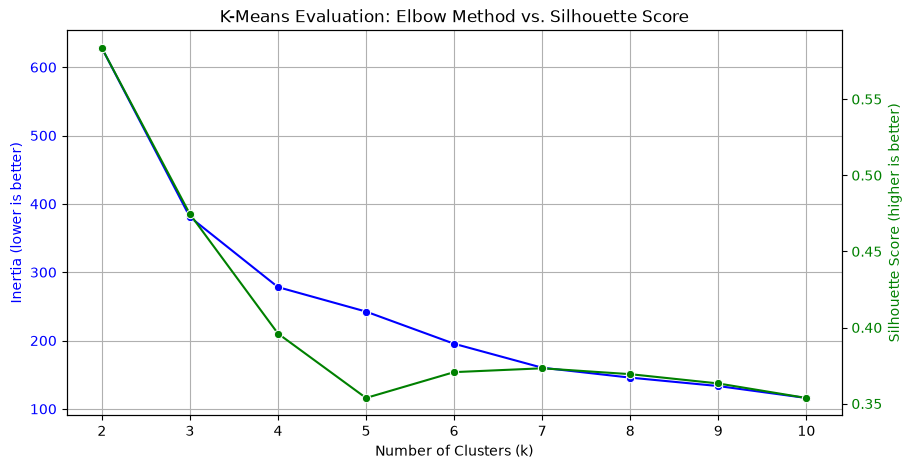

In [11]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Inertia chart on ax1
sns.lineplot(x= range(2, 11), y= inertia_values, marker= 'o', color= 'blue', ax= ax1)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia (lower is better)', color= 'blue')
ax1.tick_params(axis= 'y', labelcolor= 'blue')
ax1.grid(True)

# copy the X axis to create a right-hand axis
ax2 = ax1.twinx()

# Silhouette chart on ax2
sns.lineplot(x= range(2, 11), y= silhouette_scores, marker= 'o', color= 'green', ax= ax2)
ax2.set_ylabel('Silhouette Score (higher is better)', color= 'green')
ax2.tick_params(axis= 'y', labelcolor= 'green')

plt.title('K-Means Evaluation: Elbow Method vs. Silhouette Score')
plt.show()

### So what is our optimal K? ###

While the Silhouette score peaked at k=2, with visual inspection, we see a continuous distribution of customers rather than distinct, isolated groups.

However, a k=2 model doesn't provide enough granularity for actionable marketing strategies.

On top of that, the Elbow Method shows diminishing returns at k=4. 

Therefore, k=4 was selected instead of k=2, we are prioritizing business utility rather than mathematical specs - by dividing the continous "data" into four practical grpups. 

### Running the model again with k=4 ###

In [12]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init='auto')

final_labels = kmeans_4.fit_predict(data)

print(f"Final Inertia (k=4): {kmeans_4.inertia_}")
print(f"Final Silhouette Score (k=4): {silhouette_score(data, final_labels)}")

Final Inertia (k=4): 278.2228332422589
Final Silhouette Score (k=4): 0.39604378225837017


**Interpretations** 

As we can see, when k=2 our Inertia was around 628, with k=4 it drops to 278. 

Which means that mathematically - 4 clusters create much tighter, more focused customer profiles than 2 massive clusters.

However, by looking at the chart, the new Silhouette Score now drops from roughly 0.6 to 0.39.


## Step 5: Reporting 

### 2D Scattetplot showing the 4 customer clusters ###

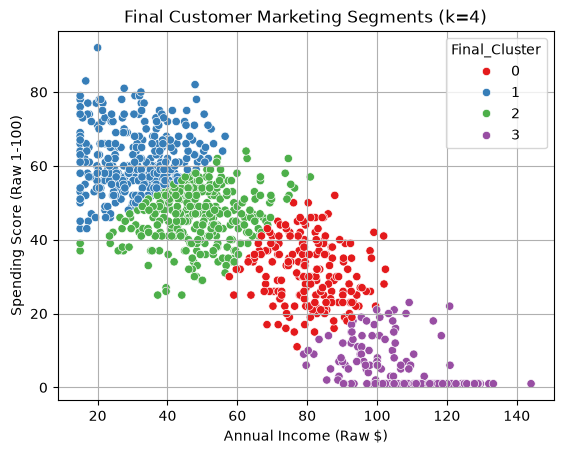

In [16]:
df_clean['Final_Cluster'] = final_labels

sns.scatterplot(
    data=df_clean, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Final_Cluster', 
    palette='Set1',  
)

plt.title('Final Customer Marketing Segments (k=4)')
plt.xlabel('Annual Income (Raw $)')
plt.ylabel('Spending Score (Raw 1-100)')
plt.grid(True)
plt.show()

### Structuring the customer profiles ###

#### Cluster 1 (Blue) ### - High Value, High Frequency Customers

**Profile:** Lower annual income (15k ~ 60k) but high spending scores (45–90)

**Behavior:** This group purchase in store frequently (and spend more) despite financial constraints, making them the most loyal shoppers

**Strategy:** Implement a loyalty program. Reward frequent visits with "streak" bonuses, flash sales, and bundle deals to maintain their high transaction volume



#### Cluster 2 (Green) ### - The Mainstream

**Profile:** Moderate annual income (30k ~ 80k) with average spending scores (30–65)

**Behavior:** These are the reliable shoppers. They do not overextend their budgets but provide a steady baseline

**Strategy:** Focus on incremental upselling, promotions or multi-store partnerships (eg. dining discounts with retail purchases) to elevate their average purchasing power

#### Cluster 3 (Red) ### - The Selective Customers

**Profile:** Higher annual income (60k ~ 100k+) but low spending scores (15–55)

**Behavior:** Despite having solid income, they don't spend much on store purchases. They likely visit strictly for specific, calculated purchases rather than recreational shopping

**Strategy:** Focus marketing toward quality and experience. Target them with new premium product lines or personalized product recommendations

#### Cluster 4 (Purple) ### The Niche Customers

**Profile:** The highest earning demographic (80k ~ $140k+) with the lowest engagement (spending scores 0–25)

**Behavior:** This group has massive financial capacity but spends almost nothing at this specific store. They may be purely transient 

**Strategy:** Capture their spending power by collaborating with ultra-premium, niche and designer brands

### Actionable Business Recommendation ###

**Target Segment:** Cluster 3 (High Income, Low Spenders)

**Data-Driven Justification:**

The K-Means clustering model (k=4) revealed a significant group of customers with high annual incomes (80k ~ 140k+) but exceptionally low store engagement (spending scores below 25). 

This suggests that price is not their barrier. 

Because they have high financial capacity but choose to withhold it, standard generic discounts will fail.

To capture their attention, the business must pivot its marketing to compete on exclusivity, novelty, and premium experiences rather than price reductions.

**Proposed Strategy:** 

**The Action:** Collaborate with premium, niche and boutique brands, such as independent designers to host short-term pop up shops within the center.

**The Marketing:** Implement a targeted advertising campaign directed and exclusively at this segment to announce these luxury pop up shops. 

It is recommended to launch this quarterly first - to measure traffic, before committing to a permanent premium retail strategy